# A03 总工时最少与团队最早完工是一回事吗？

四人同时开始、各做一项任务。你要分别求总工时最少和最晚完成时间最小的方案，再检查技能限制。

先修：已完成 AI 基础课；会使用列表、字典、函数和 NumPy。涉及的新结构在本例分步解释。

本案例所有输入来自本地；无需联网。

**环境准备：** 下一格设置本地路径、离线模式和图表字体，直接运行即可，暂时不需要掌握所有设置。真正的解题步骤从后面的中文小节开始。

In [1]:
from pathlib import Path
import os
os.environ.setdefault("HF_HUB_OFFLINE", "1")
os.environ.setdefault("TRANSFORMERS_OFFLINE", "1")
os.environ.setdefault("HF_HUB_DISABLE_TELEMETRY", "1")
os.environ.setdefault("OMP_NUM_THREADS", "2")
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
CASE_DIR = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
COURSE_ROOT = CASE_DIR.parents[1]
DATA_DIR = CASE_DIR / "data"
OUT_DIR = CASE_DIR / "outputs"
OUT_DIR.mkdir(exist_ok=True)
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
plt.rcParams.update({"font.family": "Microsoft YaHei", "axes.unicode_minus": False,
                     "figure.figsize": (8, 4.5), "figure.dpi": 110})


## 1. 用矩阵表达成员与任务
行是人，列是任务，元素是所需小时。`allowed` 是独立布尔矩阵，False代表不能接任务。数字大表示慢，不等于不允许。

In [2]:
import json
import itertools
import math
import numpy as np
import pandas as pd

def save_results(metrics, recommendation):
    """只负责保存实际计算结果；决策逻辑在下文。"""
    def convert(value):
        return value.item() if hasattr(value, "item") else str(value)
    (OUT_DIR / "metrics.json").write_text(
        json.dumps(metrics, ensure_ascii=False, indent=2, default=convert), encoding="utf-8")
    (OUT_DIR / "决策建议.md").write_text(
        "# 本次运行的决策建议\n\n" + recommendation +
        "\n\n数据为本例明确给定的教学场景；结论仅对模型、目标与已检查条件成立。\n",
        encoding="utf-8")
    print(json.dumps(metrics, ensure_ascii=False, indent=2, default=convert))
    print(recommendation)

from scipy.optimize import linear_sum_assignment
durations = np.array([[1,4,20,20],[4,6,20,20],[20,20,1,4],[20,20,4,6]], dtype=int)
allowed = np.ones_like(durations, dtype=bool)
pd.DataFrame(durations, index=["甲","乙","丙","丁"], columns=list("ABCD")).to_csv(DATA_DIR / "耗时.csv", encoding="utf-8-sig")
def check_assignment(permutation, matrix, mask):
    return (permutation is not None and len(permutation) == len(matrix)
            and sorted(permutation) == list(range(len(matrix)))
            and all(mask[i,j] for i,j in enumerate(permutation)))


## 2. 先枚举，得到可检查的基准
4!只有24种分配。`enumerate`同时给出成员编号和任务编号。总工时用sum，最晚完成用max，这两个目标不能混用。

In [3]:
def enumerate_assignment(matrix, mask, objective="sum"):
    candidates = []
    for assignment in itertools.permutations(range(len(matrix))):
        if check_assignment(assignment, matrix, mask):
            times = [int(matrix[i,j]) for i,j in enumerate(assignment)]
            score = sum(times) if objective == "sum" else max(times)
            candidates.append((score, assignment))
    return min(candidates) if candidates else (None, None)
sum_value, sum_plan = enumerate_assignment(durations, allowed, "sum")
end_value, end_plan = enumerate_assignment(durations, allowed, "max")
assert check_assignment(sum_plan, durations, allowed)
assert check_assignment(end_plan, durations, allowed)


## 3. 使用线性和指派，并独立核对
SciPy函数求的是总成本最小。给不允许的组合置无穷值；若无可行完整指派，会抛出ValueError。不能将它直接当成最晚完工时间求解器。

In [4]:
def sum_assignment(matrix, mask):
    costs = np.where(mask, matrix.astype(float), np.inf)
    try:
        rows, cols = linear_sum_assignment(costs)
    except ValueError:
        return None
    assignment = tuple(int(c) for c in cols)
    return assignment if check_assignment(assignment, matrix, mask) else None
solver_plan = sum_assignment(durations, allowed)
assert sum(durations[i,j] for i,j in enumerate(solver_plan)) == sum_value
impossible_mask = allowed.copy(); impossible_mask[0,:] = False
assert sum_assignment(durations, impossible_mask) is None
assert enumerate_assignment(durations, impossible_mask)[1] is None


## 4. 输出分工和两类目标
图的横轴是成员，条长是其耗时。所有人同时开工这一假设决定了max的含义；若有人晚到或任务有依赖，必须换模型。

In [5]:
rows = []
for label, plan in [("最少总工时", sum_plan), ("最早团队完工", end_plan)]:
    for worker, job in enumerate(plan):
        rows.append({"objective":label,"worker":worker,"task":job,"hours":int(durations[worker,job])})
table = pd.DataFrame(rows); table.to_csv(OUT_DIR / "分工对照.csv", index=False, encoding="utf-8-sig")
table.pivot(index="worker", columns="objective", values="hours").plot.bar()
plt.ylabel("工时"); plt.tight_layout(); plt.savefig(OUT_DIR / "分工.png"); plt.close()
sum_finish = max(int(durations[i,j]) for i,j in enumerate(sum_plan))
save_results({"minimum_total_hours":sum_value,"sum_optimal_finish":sum_finish,
              "minimum_finish_time":end_value,"sum_plan":sum_plan,"finish_plan":end_plan},
             f"若目标是尽早全部完成，选择{end_plan}，{end_value}小时完工；"
             f"总工时方案{sum_plan}的总耗时为{sum_value}、完工时间为{sum_finish}。先确认团队真正要优化哪个指标。")


{
  "minimum_total_hours": 14,
  "sum_optimal_finish": 6,
  "minimum_finish_time": 4,
  "sum_plan": [
    0,
    1,
    2,
    3
  ],
  "finish_plan": [
    1,
    0,
    3,
    2
  ]
}
若目标是尽早全部完成，选择(1, 0, 3, 2)，4小时完工；总工时方案(0, 1, 2, 3)的总耗时为14、完工时间为6。先确认团队真正要优化哪个指标。


## 结果图与检查
下面展示本次计算保存的图。数值以单元格和 outputs 中的实际输出为准。

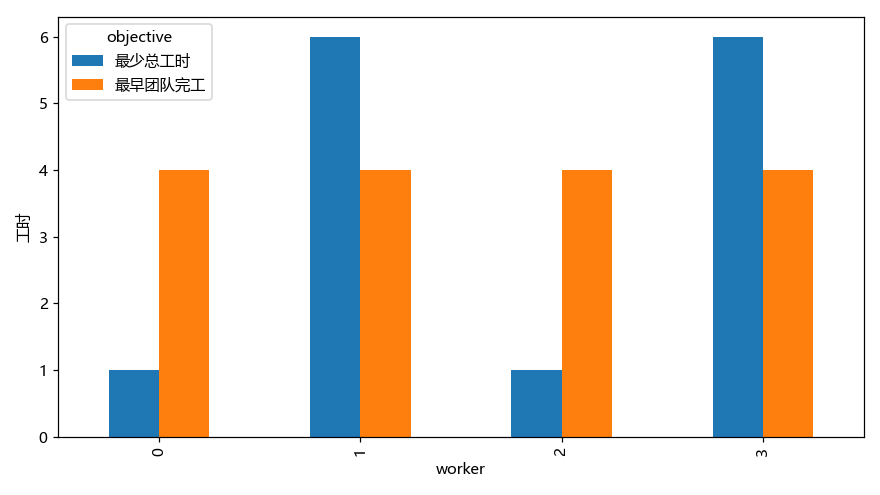

In [6]:
from IPython.display import display, Image
for figure in sorted(OUT_DIR.glob("*.png")):
    display(Image(filename=str(figure)))

## 适用边界与常见错误
本例要求人数等于任务数、每人只做一项且同时开工。存在任务依赖或多人协作时，需要调度模型。

## 独立练习
打开「动手练习.ipynb」，完成补全、修改、迁移，再查看「参考答案.ipynb」。